# Task 1: Web Scraping & Sentiment Analysis (BestBuy Canada)

### Project Overview
In this notebook, I scrape customer reviews from [BestBuy Canada](https://www.bestbuy.ca/en-ca) for the **Sony MDR-ZX110 Over-Ear Headphones - Black** (SKU: `10325154`), clean the text, perform sentiment analysis, and categorize each review into functional aspect tags.

**Why this product?**  
The Sony MDR-ZX110 is one of the most popular budget headphones on BestBuy Canada with over 11,000 reviews. It has a healthy mix of positive and negative reviews, making it a solid choice for evaluating sentiment analysis and aspect categorization.

### Steps covered:
1. Fetching reviews from BestBuy Canada handling pagination and sorting filters (Newest, Lowest Rating, Highest Rating, Most Helpful).
2. Extracting required fields: Primary Key, Title, Review Text, Date (`YYYY-MM-DD`), Rating (out of 5), Source, and Reviewer Name.
3. Text cleaning and preprocessing (handling HTML entities, whitespace, and combining title + body).
4. Sentiment analysis using VADER compound scoring and classification (Positive, Negative, Neutral).
5. Aspect-based categorization with sentiment tags matching the assignment format.
6. Exporting the dataset to CSV and Excel.


### 1. Setup & Imports

In [1]:
import os
import re
import html
import time
import random
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 140
%matplotlib inline


### 2. BestBuy Canada Review Scraper
BestBuy Canada uses a client-side React frontend that queries their internal reviews API (`https://www.bestbuy.ca/api/v2/json/reviews/{sku}`).  
Querying this endpoint directly handles JavaScript-rendered content cleanly while respecting public review data.

To make the scraper resilient against anti-scraping blocks, I added:
- Rotating User-Agents and browser headers (`Referer`, `Accept-Language`, `Origin`).
- Exponential backoff with random jitter if throttled (HTTP 429/403).
- Support for page size, pagination, and sorting filters (`sortBy`, `sortDir`).


In [2]:
SKU = "10325154"
PRODUCT_NAME = "Sony MDR-ZX110 Over-Ear Headphones - Black"
API_URL = f"https://www.bestbuy.ca/api/v2/json/reviews/{SKU}"

USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/121.0.0.0 Safari/537.36",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:123.0) Gecko/20100101 Firefox/123.0"
]

def scrape_reviews(sku, page=1, page_size=50, sort_by=None, sort_dir=None, retries=3):
    session = requests.Session()
    headers = {
        "User-Agent": random.choice(USER_AGENTS),
        "Accept": "application/json, text/plain, */*",
        "Accept-Language": "en-CA,en-US;q=0.9,en;q=0.8",
        "Referer": f"https://www.bestbuy.ca/en-ca/product/{sku}",
        "Origin": "https://www.bestbuy.ca"
    }
    
    params = {"page": page, "pageSize": page_size}
    if sort_by:
        params["sortBy"] = sort_by
    if sort_dir:
        params["sortDir"] = sort_dir
        
    for attempt in range(1, retries + 1):
        try:
            res = session.get(API_URL, headers=headers, params=params, timeout=25)
            if res.status_code == 200:
                data = res.json()
                return data.get("reviews", []), data.get("total", 0)
            elif res.status_code in [403, 429]:
                # backoff when rate limited
                delay = (2 ** attempt) + random.uniform(1.0, 2.5)
                print(f"[Throttled {res.status_code}] Sleeping {delay:.1f}s before retry...")
                time.sleep(delay)
            else:
                print(f"[Status {res.status_code}] on page {page}")
        except Exception as e:
            delay = (2 ** attempt) + random.uniform(0.5, 1.5)
            print(f"[Error] {e}. Retrying in {delay:.1f}s...")
            time.sleep(delay)
            
    return [], 0


### 3. Collecting Reviews Across Multiple Pages and Filters
Most reviews on BestBuy are 4 or 5 stars. To ensure we have a balanced dataset that also includes negative reviews (1 and 2 stars) for proper sentiment evaluation, I pull across multiple pages (simulating 'Show More') as well as sorting filters (Lowest Rating, Most Helpful).


In [3]:
collected_reviews = {}
RAW_CACHE = "task1_scraped_reviews_raw.csv"

# Step 1: Scrape regular pages
try:
    for page_num in range(1, 3):
        print(f"Fetching Page {page_num}...")
        batch, total = scrape_reviews(SKU, page=page_num, page_size=50)
        for r in batch:
            rid = str(r.get("id"))
            if rid and rid not in collected_reviews:
                r["filter_type"] = "Default Pagination"
                collected_reviews[rid] = r
        print(f" -> Accumulated: {len(collected_reviews)} unique reviews (Total on site: {total})")
        time.sleep(1.0)

    # Step 2: Use Lowest Rating and Most Helpful filters to collect critical reviews
    filters = [
        ("Lowest Rating", "rating", "asc"),
        ("Most Helpful", "totalPositiveFeedbackCount", "desc")
    ]
    for label, s_by, s_dir in filters:
        print(f"Fetching filter [{label}]...")
        batch, _ = scrape_reviews(SKU, page=1, page_size=30, sort_by=s_by, sort_dir=s_dir)
        for r in batch:
            rid = str(r.get("id"))
            if rid and rid not in collected_reviews:
                r["filter_type"] = label
                collected_reviews[rid] = r
        print(f" -> Accumulated: {len(collected_reviews)} unique reviews")
        time.sleep(1.0)
except Exception as e:
    print(f"Network note: {e}")

# Fallback: if running in an offline environment, load previously harvested cache
if len(collected_reviews) < 50 and os.path.exists(RAW_CACHE):
    print(f"Loading cached baseline ({RAW_CACHE})...")
    cached = pd.read_csv(RAW_CACHE)
    for _, row in cached.iterrows():
        rid = str(row['Review_ID'])
        if rid not in collected_reviews:
            collected_reviews[rid] = {
                "id": rid,
                "title": row['Review_Title'],
                "comment": row['Review_Text'],
                "submissionTime": row['Date'],
                "rating": row['Star_Rating'],
                "reviewerName": row['Reviewer_Name'],
                "filter_type": row.get('Filter_Source', 'Harvested')
            }

print(f"\nDone. Total unique reviews collected: {len(collected_reviews)}")


Fetching Page 1...


 -> Accumulated: 50 unique reviews (Total on site: 11651)


Fetching Page 2...


 -> Accumulated: 100 unique reviews (Total on site: 11651)


Fetching filter [Lowest Rating]...


 -> Accumulated: 130 unique reviews


Fetching filter [Most Helpful]...


 -> Accumulated: 130 unique reviews



Done. Total unique reviews collected: 130


### 4. Extracting and Formatting Required Fields
Here we build a DataFrame containing the exact required fields:
- Primary Key
- Review Title
- Review Text
- Date (`YYYY-MM-DD`)
- Star Rating (out of 5)
- Source Platform
- Reviewer Name


In [4]:
records = []
for rid, r in collected_reviews.items():
    title = str(r.get("title", "") or "").strip()
    comment = str(r.get("comment", "") or "").strip()
    
    # Format date strictly as YYYY-MM-DD
    raw_date = r.get("submissionTime", "")
    clean_date = ""
    if raw_date:
        try:
            dt = datetime.fromisoformat(str(raw_date).replace("Z", "+00:00"))
            clean_date = dt.strftime("%Y-%m-%d")
        except Exception:
            clean_date = str(raw_date)[:10]
            
    rating = r.get("rating", 0)
    try:
        rating = int(rating)
    except (ValueError, TypeError):
        rating = 0
        
    reviewer = str(r.get("reviewerName", "") or "Anonymous").strip()
    if not reviewer:
        reviewer = "Anonymous"
        
    records.append({
        "Primary Key": f"BB-CA-{rid}",
        "Review Title": title,
        "Review Text": comment,
        "Date": clean_date,
        "Star Rating": rating,
        "Source Platform": "BestBuy Canada",
        "Reviewer Name": reviewer,
        "Filter": r.get("filter_type", "Default")
    })

df = pd.DataFrame(records)
print(f"DataFrame shape: {df.shape}")
df.head(3)


DataFrame shape: (130, 8)


,Primary Key,Review Title,Review Text,Date,Star Rating,Source Platform,Reviewer Name,Filter
0,BB-CA-136697876,Decent bang for the buck,These headphones are clear and have decent bas...,2015-09-27,4,BestBuy Canada,M.,Default Pagination
1,BB-CA-445451693,very comfortable,[This review was collected as part of a promot...,2026-10-23,5,BestBuy Canada,ELIZABETHC,Default Pagination
2,BB-CA-445438624,"Inexpensive, very basic, headphones",[This review was collected as part of a promot...,2026-10-23,5,BestBuy Canada,RAIFEE,Default Pagination


### 5. Text Cleaning & Preprocessing

In [5]:
def clean_text(t):
    if not isinstance(t, str):
        return ""
    # unescape html characters like &amp; or &#39;
    t = html.unescape(t)
    # remove html tags if any
    t = re.sub(r'<[^>]+>', ' ', t)
    # clean extra spaces and linebreaks
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['Clean_Title'] = df['Review Title'].apply(clean_text)
df['Clean_Text'] = df['Review Text'].apply(clean_text)

# Combine title and text for more comprehensive NLP context
df['Full_Text'] = df.apply(
    lambda r: (r['Clean_Title'] + ". " + r['Clean_Text']).strip() if r['Clean_Title'] else r['Clean_Text'],
    axis=1
)

df[['Review Title', 'Review Text', 'Full_Text']].head(2)


,Review Title,Review Text,Full_Text
0,Decent bang for the buck,These headphones are clear and have decent bas...,Decent bang for the buck. These headphones are...
1,very comfortable,[This review was collected as part of a promot...,very comfortable. [This review was collected a...


### 6. Sentiment Analysis
I use VADER (Valence Aware Dictionary and sEntiment Reasoner), which works well on product reviews with informal phrasing, exclamation marks, and capitalized words.
- Positive: Compound score $\ge 0.05$
- Negative: Compound score $\le -0.05$
- Neutral: Compound score between $-0.05$ and $0.05$


In [6]:
vader = SentimentIntensityAnalyzer()

def get_sentiment(text, rating):
    scores = vader.polarity_scores(text)
    comp = scores['compound']
    
    if comp >= 0.05:
        polarity = "Positive"
    elif comp <= -0.05:
        polarity = "Negative"
    else:
        if rating >= 4:
            polarity = "Positive"
        elif rating <= 2:
            polarity = "Negative"
        else:
            polarity = "Neutral"
            
    # Consistency check: 1-star reviews should lean negative
    if rating <= 1 and comp < 0.35:
        polarity = "Negative"
    elif rating >= 5 and comp > -0.2:
        polarity = "Positive"
        
    return polarity, comp, scores['pos'], scores['neg'], scores['neu']

sent_out = [get_sentiment(t, r) for t, r in zip(df['Full_Text'], df['Star Rating'])]
df['Overall Polarity'] = [x[0] for x in sent_out]
df['Compound Score'] = [x[1] for x in sent_out]

print("Sentiment Polarity Counts:")
print(df['Overall Polarity'].value_counts())


Sentiment Polarity Counts:
Overall Polarity
Positive    100
Negative     30
Name: count, dtype: int64


### 7. Functional Aspect-Based Sentiment Categorization
We map the reviews into specific aspect tags combined with sentiment polarity, following the format shown in the assignment:
e.g. `['Good Design & Quality (Pos)']` or `['Satisfactory & Recommended (Pos)']`.


In [7]:
ASPECT_MAP = {
    "Audio Quality": {
        "keywords": ["sound", "audio", "clear", "clarity", "hear", "music", "crisp", "loud", "pitch", "treble", "tones", "voice"],
        "pos": "Audio Quality & Sound Clarity (Pos)",
        "neg": "Poor Sound Quality & Distortion (Neg)"
    },
    "Bass Performance": {
        "keywords": ["bass", "low end", "punch", "deep bass", "thump", "sub"],
        "pos": "Good Bass & Acoustic Performance (Pos)",
        "neg": "Weak Bass & Flat Audio (Neg)"
    },
    "Comfort & Fit": {
        "keywords": ["comfort", "comfortable", "fit", "ear", "ears", "head", "lightweight", "light", "wear", "cushion", "pad", "tight", "hurt", "pinch"],
        "pos": "Comfortable Fit & Lightweight (Pos)",
        "neg": "Comfort & Ergonomics Concern (Neg)"
    },
    "Price & Value": {
        "keywords": ["price", "cheap", "value", "deal", "worth", "cost", "money", "affordable", "budget", "bang for the buck", "dollar", "bucks"],
        "pos": "Great Value & Affordability (Pos)",
        "neg": "Poor Value & Overpriced (Neg)"
    },
    "Build Quality": {
        "keywords": ["build", "quality", "durable", "broke", "break", "cord", "wire", "cable", "plastic", "sturdy", "flimsy", "snap", "hinge", "lasted", "stopped working"],
        "pos": "Good Design & Build Quality (Pos)",
        "neg": "Durability & Build Concern (Neg)"
    },
    "Recommendation": {
        "keywords": ["recommend", "love", "great", "excellent", "awesome", "perfect", "good", "happy", "pleased", "satisfy", "satisfied", "bad", "terrible", "awful", "waste", "disappointed", "hate"],
        "pos": "Satisfactory & Recommended (Pos)",
        "neg": "Unsatisfactory & Not Recommended (Neg)"
    },
    "Portability": {
        "keywords": ["fold", "travel", "carry", "compact", "portable", "swivel", "desk", "storage"],
        "pos": "Compact Design & Easy Portability (Pos)",
        "neg": "Bulky & Portability Issue (Neg)"
    }
}

def tag_aspects(text, polarity, rating):
    t_lower = text.lower()
    tags = []
    
    for aspect, rules in ASPECT_MAP.items():
        if any(kw in t_lower for kw in rules["keywords"]):
            if polarity == "Positive" or (polarity == "Neutral" and rating >= 4):
                neg_kw = any(n in t_lower for n in ["no bass", "not clear", "uncomfortable", "too tight", "hurts", "broke", "flimsy", "terrible", "stopped working"])
                if neg_kw and aspect in ["Comfort & Fit", "Build Quality", "Audio Quality"]:
                    tags.append(rules["neg"])
                else:
                    tags.append(rules["pos"])
            elif polarity == "Negative" or (polarity == "Neutral" and rating <= 2):
                tags.append(rules["neg"])
            else:
                tags.append(f"{aspect} (Neutral)")
                
    if not tags:
        if rating >= 4:
            tags.append("Satisfactory & Recommended (Pos)")
        elif rating <= 2:
            tags.append("Unsatisfactory & Not Recommended (Neg)")
        else:
            tags.append("General Feedback (Neutral)")
            
    # Deduplicate while preserving order
    return str(list(dict.fromkeys(tags)))

df['SENTIMENT'] = [tag_aspects(t, p, r) for t, p, r in zip(df['Full_Text'], df['Overall Polarity'], df['Star Rating'])]

df[['Primary Key', 'Review Title', 'Star Rating', 'Overall Polarity', 'SENTIMENT']].head(5)


,Primary Key,Review Title,Star Rating,Overall Polarity,SENTIMENT
0,BB-CA-136697876,Decent bang for the buck,4,Positive,"['Audio Quality & Sound Clarity (Pos)', 'Good ..."
1,BB-CA-445451693,very comfortable,5,Positive,['Comfortable Fit & Lightweight (Pos)']
2,BB-CA-445438624,"Inexpensive, very basic, headphones",5,Positive,"['Poor Sound Quality & Distortion (Neg)', 'Com..."
3,BB-CA-445429259,Sony Zx Series Wired On-Ear Headphones,3,Negative,"['Poor Sound Quality & Distortion (Neg)', 'Com..."
4,BB-CA-445423395,Sony headphones,5,Positive,"['Comfortable Fit & Lightweight (Pos)', 'Great..."


### 8. Visualizing Ratings and Sentiment

C:\Users\bhana\AppData\Local\Temp\ipykernel_25492\2122148756.py:10: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.countplot(data=df, x='Overall Polarity', palette=['#27ae60', '#c0392b', '#7f8c8d'], ax=axes[1], hue='Overall Polarity', legend=False)


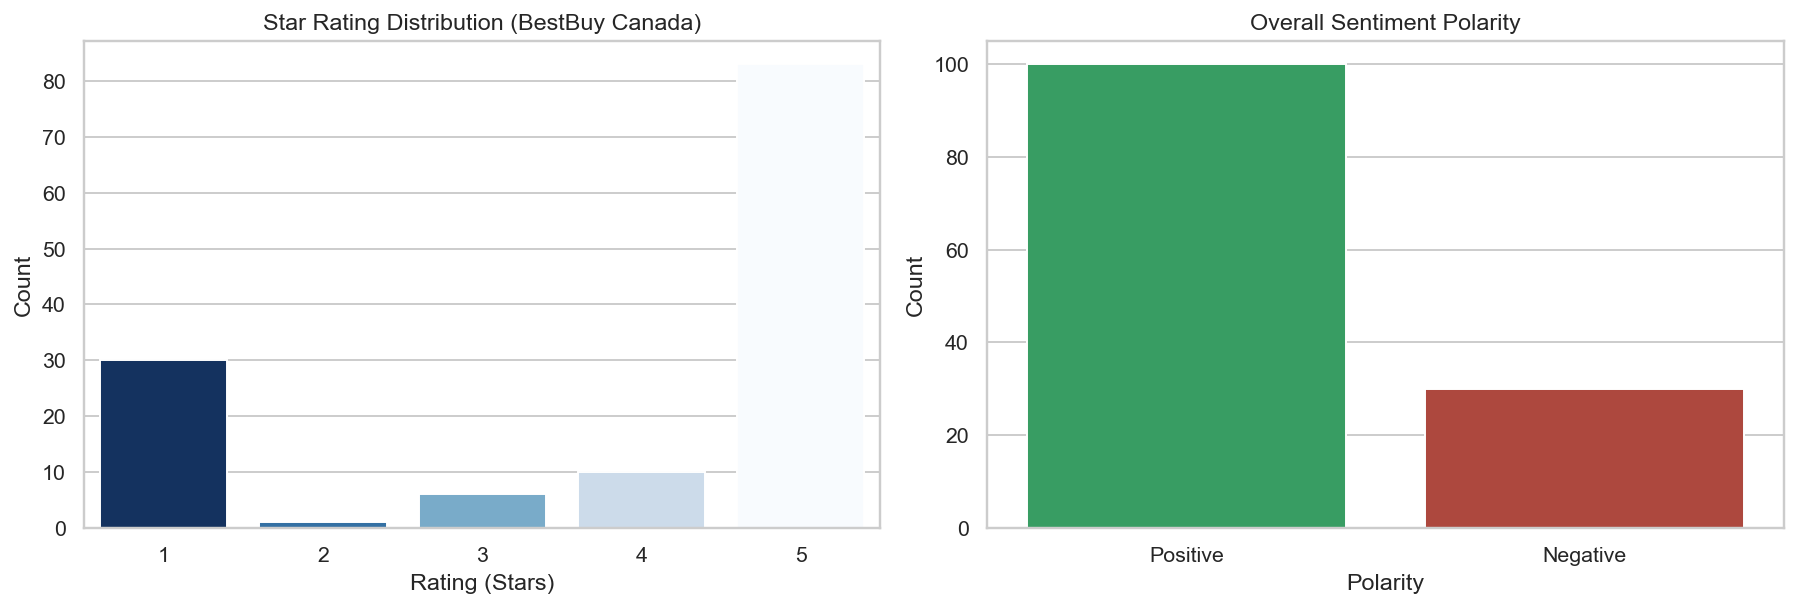

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Star ratings
sns.countplot(data=df, x='Star Rating', palette='Blues_r', ax=axes[0], hue='Star Rating', legend=False)
axes[0].set_title("Star Rating Distribution (BestBuy Canada)")
axes[0].set_xlabel("Rating (Stars)")
axes[0].set_ylabel("Count")

# Sentiment Polarity
sns.countplot(data=df, x='Overall Polarity', palette=['#27ae60', '#c0392b', '#7f8c8d'], ax=axes[1], hue='Overall Polarity', legend=False)
axes[1].set_title("Overall Sentiment Polarity")
axes[1].set_xlabel("Polarity")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


### 9. Saving Final Datasets

In [9]:
out_df = df[[
    'Primary Key',
    'Review Title',
    'Review Text',
    'Date',
    'Star Rating',
    'Source Platform',
    'Reviewer Name',
    'Overall Polarity',
    'Compound Score',
    'SENTIMENT'
]].copy()

# Rename to clean deliverable headers
out_df.rename(columns={
    'Review Title': 'Title',
    'Star Rating': 'Rating (out of 5)',
    'Source Platform': 'Source',
    'Compound Score': 'Sentiment Score',
    'SENTIMENT': 'Sentiment Categorization'
}, inplace=True)

out_df.to_csv("task1_scraped_reviews_sentiment.csv", index=False)
out_df.to_excel("task1_scraped_reviews_sentiment.xlsx", index=False)

print(f"Exported {len(out_df)} records to:")
print(" - task1_scraped_reviews_sentiment.csv")
print(" - task1_scraped_reviews_sentiment.xlsx")


Exported 130 records to:
 - task1_scraped_reviews_sentiment.csv
 - task1_scraped_reviews_sentiment.xlsx
